# SQChip-EM 1-qubit template: a Quantcore-PDK rebuild, step by step

**Source:** Secbrain, *SQChip-EM*, the layout-to-EM dataset (DOI 10.5281/zenodo.20489133), from
`chip_code/metal_KDD_1qubit.py` (`LayoutParams`, `populate_design`) and `data/sqchip_em_1q/summary.csv`,
<https://github.com/Secbrain/SQChip-EM>. The repo states no licence; it is rebuilt regardless (decision, 2026-11-03), credited
here and distributed under the GPL. Spec: `docs/designs/community/sqchip_em.md`.

**What the chip is:** the 1-qubit Qiskit Metal template behind the dataset's 532 HFSS/Q3D rows:
- a `TransmonPocket` (pads 520 µm, pocket height 780 µm, readout pad 180 × 150 µm);
- an 8.5 mm λ/2 readout, capacitive at both ends;
- a `CapNInterdigitalTee` (12 fingers, 160 µm long, 1.2 µm gap) to a 5.5 mm feed meander from one launchpad.

In the dataset only the qubit position varies (L_J 12 nH, C_J 2 fF). At dx = dy = 0: f_q 4.734 GHz, f_r 6.099 GHz,
g/2π 200–294 MHz, κ/2π 5.3–6.1 MHz, C_in ≈ 52 fF.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (SQChip-EM) | this rebuild |
|---|---|---|
| die and frame | 12 mm Metal canvas, mostly empty, no frame | PDK 7.5 mm die: dicing L's, alignment grids, device ID `SQCHIP-1Q` |
| stack | silicon (HFSS) | PDK sapphire 650 µm, εr 10.25 |
| qubit, tee, launchpad | Metal cells and options | the same cells through the `metal:` wrappers, same options |
| junction | lumped L_J 12 nH, C_J 2 fF | Quantcore Nb trilayer junction drawn for L_J = 12 nH (`trilayer_junction`); R_n is flagged, not retuned |
| readout and feed | Metal meanders, 8.5 mm λ/2 and 5.5 mm feed | qcc meanders of the same lengths |
| launchpad position | 2.4 mm west of the tee, well inside the canvas | **PDK pad rule**: slid west until its etch is `frame.pad_edge` = 100 µm from the die edge (same height) |
| placement | the canvas is centred on the qubit | **PDK**: the qubit, readout and tee are centred in the die |
| cheese | none (`GDS_DISABLE_CHEESE = True` in the source) | **PDK band** (`cheese: "auto"`): the original has none |
| netlist, LOM, FEM jobs | HFSS/Q3D rows | our netlist, LOM and Q3D / eigenmode job exports |

**Use:** a LOM cross-check against the dataset row. The dataset is silicon and HFSS, this is sapphire and LOM, so
expect f_r a few percent higher and g of the same order.

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

The PDK facts this chip relies on. Every rule below is applied by the library, not by this notebook: the frame and
the cheese are drawn by the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, and the PDK
design warnings come out of the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws its frame round it: the L dicing
markers in the corners (layer 1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID
(`name_chip`) on a free edge. The source's 12 mm canvas is mostly empty, so the rebuild uses the PDK's standard
7.5 mm die.

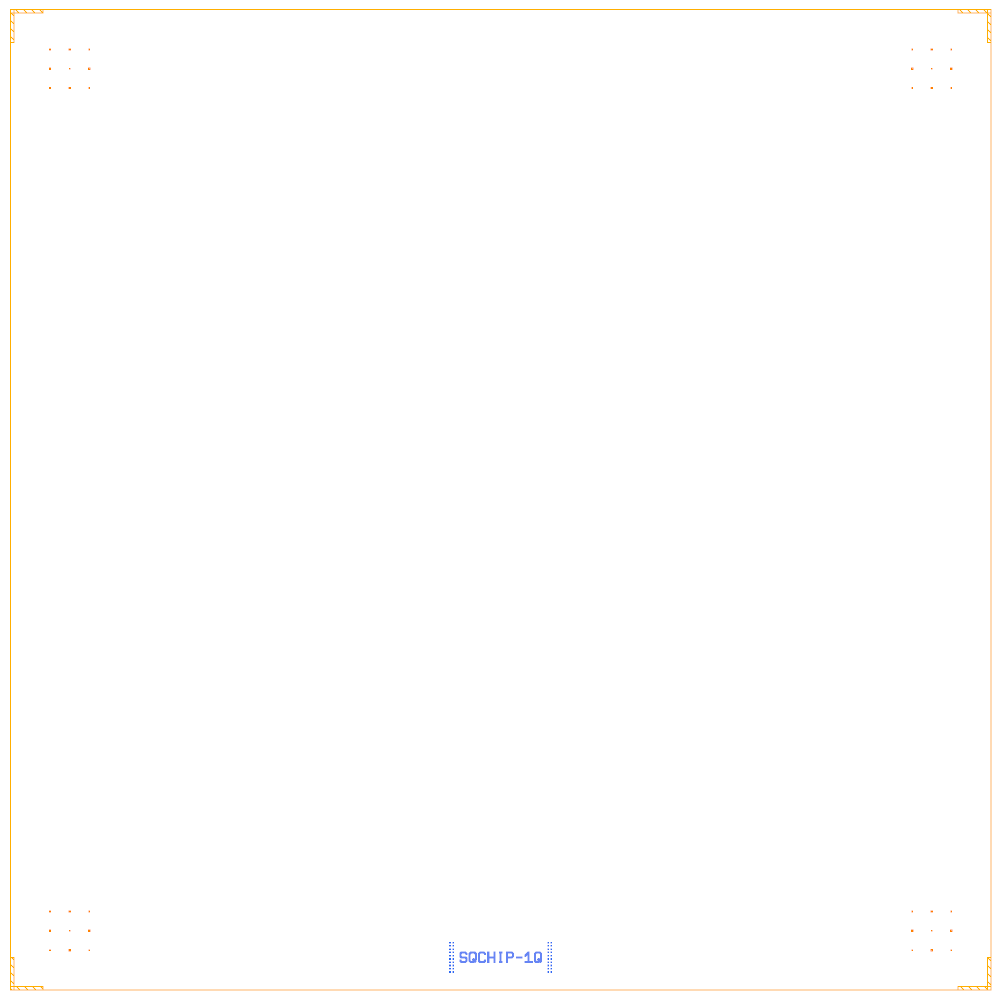

In [3]:
d = Designer("sqchip_em", box=(0, 0, 7500, 7500), chip={"name_chip": "SQCHIP-1Q"}, live=LIVE)
snap(d, OUT / "sqchip_em_die.png", size=(1000, 1000), width=360);

## 3 · Components: the pocket transmon and its junction

**The junction.** The dataset fixes L_J = 12 nH. `trilayer_junction(cell, lj_nH=12)` returns two things:
- the cell parameters that draw a Quantcore Nb/AlOx/Nb trilayer junction (fingers on 2/0 and 4/0, spacer 50/0 with the
  51–53/0 dose gradient) sized for that L_J on the PDK junction rule;
- the junction values the LOM uses (L_J and C_J of the drawn junction).

At 12 nH the junction is small, so R_n ≈ 80 kΩ, **outside the PDK window of 40–50 kΩ**. Following the project rule
(values are flagged, never retuned), the dataset's L_J stays and the DRC reports it as the design warning `pdk_rn`.

In [4]:
LJ_NH = 12.0                                     # the dataset's Lj (every 1q row)
JJP, JJ = trilayer_junction("metal:TransmonPocket", lj_nH=LJ_NH)
print("cell parameters:", JJP)
print("LOM junction:   ", JJ, f"→ R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 12.0}}
LOM junction:    {'Lj_nH': 12.0258, 'Cj_fF': 8.4} → R_n 80.4 kΩ (PDK window 40–50 kΩ)


**The qubit.** The source's `LayoutParams` give the pocket: 520 µm pads in a 780 µm pocket, with one readout
connection pad (180 × 150 µm, 1.4 µm gap) at the top right. The Metal cell is used through the `metal:` wrapper, so its
options and pins are Metal's; `q.readout` is the readout pad's pin.

In [5]:
POCKET = dict(pad_width=520, pocket_height=780,   # LayoutParams; readout pad = the dataset rows' 180 × 150, gap 1.4
              connection_pads={"readout": dict(loc_W=+1, loc_H=+1, pad_width=180, pad_height=150, pad_gap=1.4)})
X0 = Y0 = 3750.0                                 # the source's canvas is centred on Q1 (dataset row dx = dy = 0)
q = d.add("Q1", "metal:TransmonPocket", at=(X0, Y0), junction=JJ, **POCKET, **JJP)
print(q)
print("readout pin:", port_xy(d, "Q1.readout"))

<metal:TransmonPocket Q1 ports=['readout', 'squid_a', 'squid_b']>
readout pin: (4175.0, 3931.4)


**The interdigital tee.** The dataset's tee (12 fingers, 160 µm long, 1.2 µm gap) joins the feed (`prime_start`) to the
readout (`second_end`). The source puts it at the readout pin + (1.0, 2.0) mm. Its `prime_end` stays open, as in the
source.

<metal:CapNInterdigitalTee RO_TEE ports=['prime_end', 'prime_start', 'second_end']>


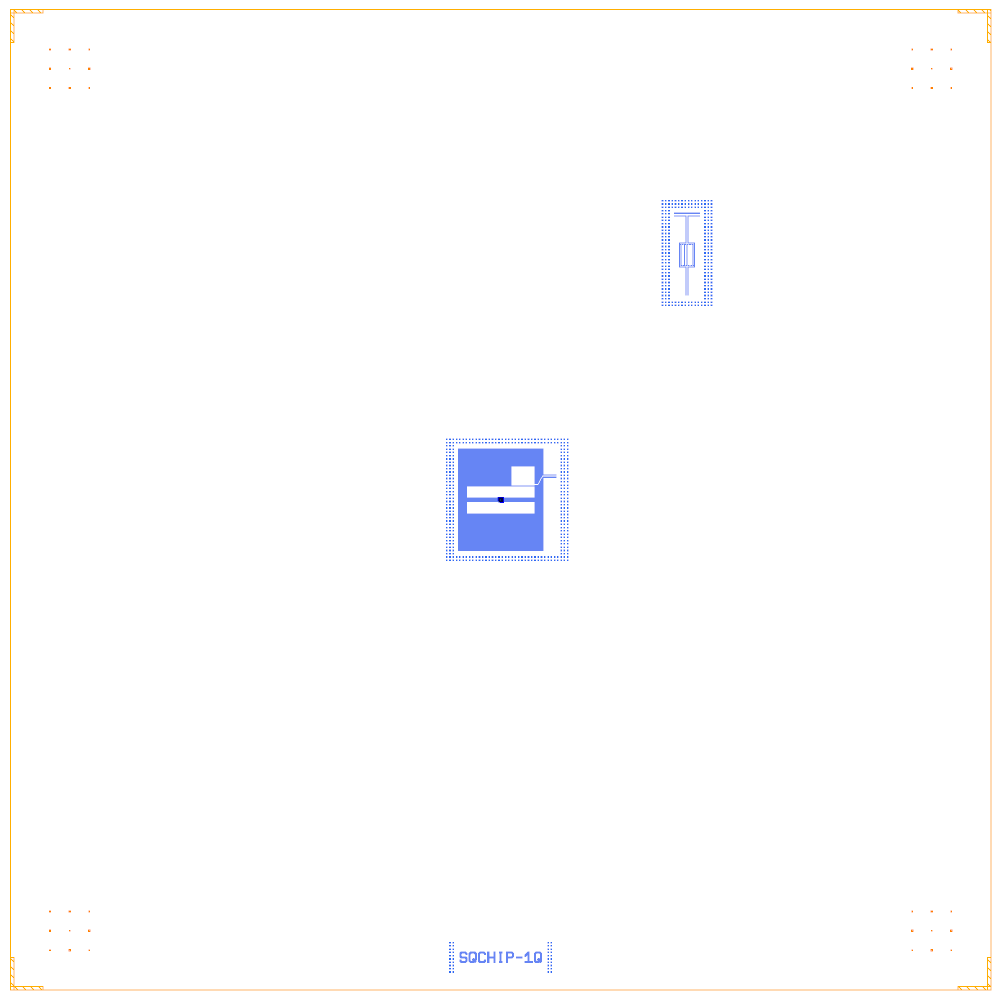

In [6]:
TEE = dict(prime_width=14, prime_gap=6, second_width=10, second_gap=6, cap_gap=1.2, cap_width=8,
           finger_length=160, finger_count=12, cap_distance=220)      # dataset tee: fl160, fc12, cg1.2
rx, ry = port_xy(d, "Q1.readout")                # Metal: pins["readout"]["middle"]
tee = d.add("RO_TEE", "metal:CapNInterdigitalTee", at=(rx + 1000, ry + 2000), **TEE)
print(tee)
snap(d, OUT / "sqchip_em_components.png", size=(1000, 1000), width=360);

## 4 · Routes: the λ/2 readout

`d.route(name, from_port, to_port, meander=L)` draws a CPW (PDK default 10/6 µm unless given) of total length `L`
between two ports; the router adds the meander. The readout is the source's 8.5 mm λ/2 between the tee's second end
and the qubit's readout pad, with 6 meanders and 25 µm bends (Metal's spacing 280 µm).

In [7]:
ro = d.route("RO_RES", tee.second_end, q.readout, meander=8500, r=25).set(meanders=6)   # λ/2, capacitive at both ends
rebuild(d)
print(f"RO_RES drawn length: {ro.length:.1f} µm")

RO_RES drawn length: 8500.0 µm


## 5 · PDK placement: centre the content, then the pad rule

**Centring.** The PDK wants the chip content in the middle of the die. `center_in_die(d)` measures the bounding box
of every instance and route and shifts them all (instance positions, route waypoints) so that box is centred. The
qubit, the readout and the tee are centred here, before the launchpad is added: the launchpad is pinned to the die
edge by the pad rule, so it cannot take part in the centring. This run: the
core moves by (−598, −902) µm.

In [8]:
shift = center_in_die(d)
print("shift applied (µm):", shift)
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
print("Q1 now at", (qx, qy))

shift applied (µm): (-598.0, -902.2)
Q1 now at (3152.0, 2847.8)


**The pad rule.** The source's launchpad sits 2.4 mm west of the tee, at the tee's height. The PDK puts every bond pad
and launcher with the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**. `edge="w"` slides
the pad perpendicular to the west edge until that holds; its position along the edge (y) is kept. `pads_md(d)` lists
each pad's distance to the nearest edge.

In [9]:
tx, ty = port_xy(d, "RO_TEE.prime_start")
lp = d.add("LP_RO", "metal:LaunchpadWirebond", at=(tx - 2400, ty), edge="w", trace_width=10, trace_gap=6)
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_RO | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |

**The feed.** The source's 5.5 mm feed meander runs from the launchpad's `tie` to the tee's `prime_start`. Its length
is kept; with the launchpad now at the die edge it needs fewer meanders.

{'RO_RES': 8500.0, 'RO_FEED': 5500.0}


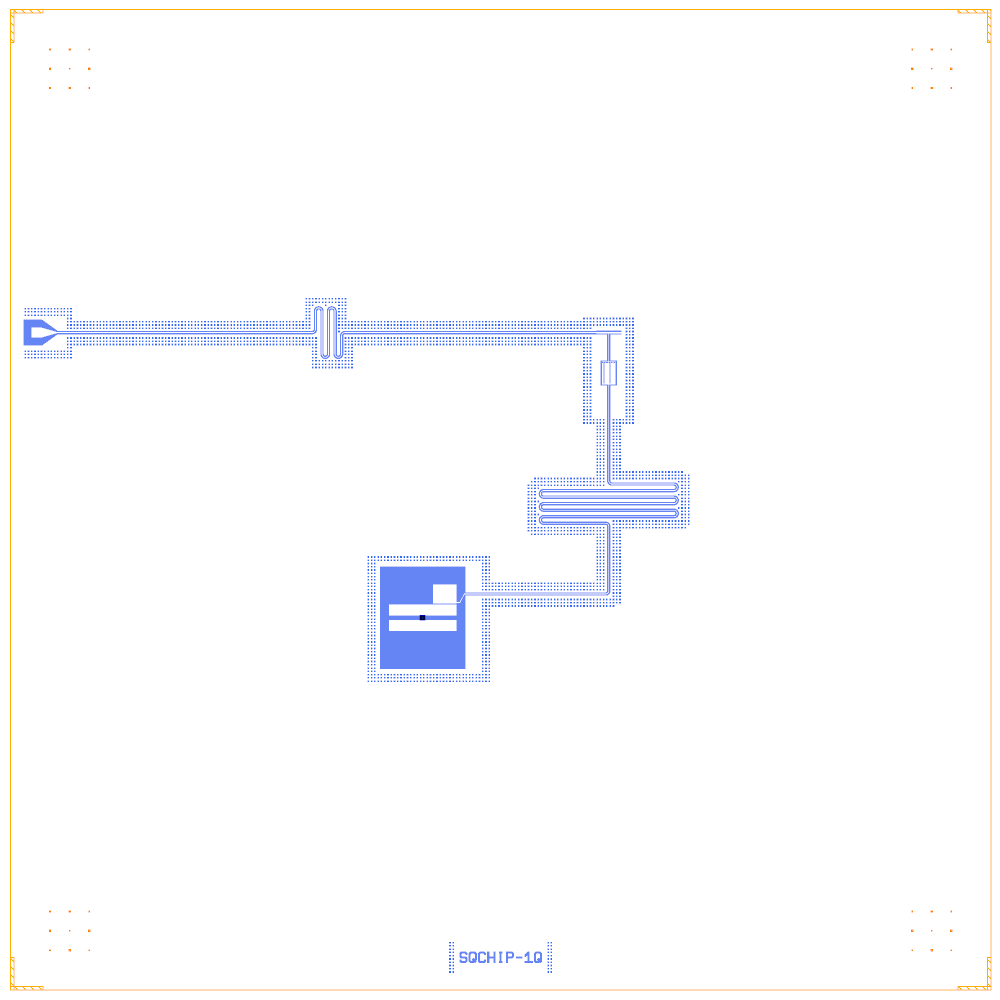

In [10]:
feed = d.route("RO_FEED", lp.tie, tee.prime_start, meander=5500, r=25).set(meanders=4)
d.sim_group("Q1R", ["Q1", "RO_RES", "RO_TEE"])                                   # FEM: qubit + readout + tee
d.targets(Q1={"f_q_GHz": 4.734}, RO_RES={"f_GHz": 6.099})                         # dataset row dx = dy = 0
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "sqchip_em_routes.png", size=(1000, 1000), width=360);

## 6 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong (a short, a route through a component); there must be none;
- **warnings** are worth a look but can be intended: here the junction attachment points (`squid_a` / `squid_b`, the
  cell draws its own junction) and the tee's open `prime_end`, as in the source;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced.

Expected (this run): **no errors**; 3 `dangling_port` warnings (`squid_a`, `squid_b` and the tee's open `prime_end`);
one `pdk_rn` (R_n 80.4 kΩ). No `pad_edge`: the launchpad sits at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 3 warnings · 1 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 3 | Q1.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 1 | Q1: junction R_n 80.4 kΩ is outside the PDK window 40–50 kΩ (L_J 12.0258 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (-1364, +42) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | Q1: junction R_n 80.4 kΩ is outside the PDK window 40–50 kΩ (L_J 12.0258 nH) |

The content centre is west of the die centre because the launchpad is pinned to the west edge; the qubit, readout and
tee themselves are centred (step 5); this run: (−1364, +42) µm, the launchpad and the 5.5 mm feed pulling it west. The one design warning is the 80 kΩ junction (dataset L_J kept).

## 7 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: every component's LOM model maps its ports to circuit nodes, and
every route becomes a wire, a resonator or a coupling. Here:
- the floating pocket transmon: two pad nodes (`Q1.island1`, `Q1.island2`) and the trilayer junction between them;
- the readout pad's coupling capacitance to the near pad;
- the λ/2 readout `TLres` between the qubit pad and the tee's second end;
- the IDC between the tee's coupled node and the feed node;
- one 50 Ω port at the launchpad.

In [12]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**5 nodes · 12 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `RO_TEE.second_end` |
| `RO_TEE.prime` | `RO_TEE.prime`, `LP_RO.pad` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 42.2 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 42.2 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 34.3 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 12 nH, Cj 8.4 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 37 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 3.9 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 59.9 fF |
| `C_RO_TEE` | C | `RO_TEE.prime` – `Q1.readout` | 170 fF |
| `C_RO_TEE_second` | C | `Q1.readout` – `gnd` | 33 fF |
| `Port_LP_RO` | R | `RO_TEE.prime` – `gnd` | 50 Ω |
| `RO_RES` | TLres | `Q1.readout` – `gnd` | lambda/2, 8500 µm, 7.414 GHz |
| `RO_FEED` | TLres | `RO_TEE.prime` – `gnd` | lambda/2, 5500 µm, 11.458 GHz |

**Unconnected ports:** `RO_TEE.prime_end`

{'nodes': 4, 'branches': 12, 'controls': 0, 'unconnected': 1}


## 8 · LOM simulation vs the dataset row (dx = dy = 0)

`simulate_groups` builds a QuCat network from the netlist (normal modes, κ, participations) and diagonalises the
circuit Hamiltonian in QuTiP (dressed f_q, α, f_r, χ). Targets are in brackets. The dataset gives f_q 4.734 GHz and
f_r 6.099 GHz on silicon (HFSS); on sapphire with LOM estimates, expect f_r a little higher and a large χ (g is
≈ 0.2–0.3 GHz in the dataset).

What the tables show (this run): f_q **5.118 GHz** (+8 % on the dataset's 4.734: the drawn trilayer junction is
12.03 nH with C_J 8.4 fF and the LOM pocket estimate differs from HFSS), α −301 MHz; f_r **6.1245 GHz** (+0.4 %);
χ −8.37 MHz. κ is **93.4 MHz**, far above the dataset's 5.3–6.1 MHz: the LOM estimate of an IDC with 1.2 µm
gaps is too large (a request to the LOM owner); a Q3D run of the tee fixes it (steps 9–10).

In [13]:
GROUP = ["Q1", "RO_RES", "RO_TEE", "RO_FEED", "LP_RO"]
res = simulate_groups(d, {"Q1R": GROUP}, max_modes=2)
display(Markdown(modes_md(res["Q1R"]) + "\n\n" + groups_md(res, d.data["targets"])))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.3963 | 1.52 | 251.9 | J_Q1 0.97, RO_RES 0.03 |
| RO_RES | resonator | 6.1315 | 93.4 | 0.3 | RO_RES 0.97, J_Q1 0.03 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R | Q1 | 5.1178 (4.734) | -301.3 | RO_RES | 6.1245 (6.099) | 93.4 | -8.37 |

## 9 · FEM: send the job

The sim group `Q1R` (qubit, readout, tee) is exported as two jobs: a Q3D C-matrix job (capacitances by net name) and
an eigenmode/EPR job. The job folders are self-contained (`build/jobs/<design>_<group>_<analysis>`); exporting again
replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs`
solves each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [14]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "sqchip_em.json")
jobs = export_sims(DESIGN, ["Q1R"], analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, ["Q1R"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["Q1R"], analyses=["q3d_cmatrix", "eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R | `build/jobs/sqchip_em_Q1R_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `RO_TEE.second_end`<br>3 · waveguide · `Q1.readout`<br>4 · edge · `RO_FEED` | `Q1.island2`, `RO_TEE.second_end`, `Q1.readout`, `Q1.island1` |
| Q1R | `build/jobs/sqchip_em_Q1R_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `RO_FEED` | `Q1.island2`, `RO_FEED`, `Q1.island1`, `Q1.readout` |

## 10 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name (`Q1.island1`, `Q1.island2`, the tee and readout nets), next to the estimates,
and the LOM can be simulated again on them. Until a solve has run, the cell says what would appear.

In [15]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for Q1R · q3d, Q1R · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 11 · Iterate: change one property and re-simulate

The LOM is cheap, so a design change can be checked in seconds. Here the tee's finger count goes from 12 to 6: the IDC
capacitance roughly halves, so the readout's κ (through the tee, κ ∝ C²) drops about threefold, and the readout moves
up because the IDC no longer loads its open end as much. This run: κ 93.4 → 28.7 MHz, f_r 6.1245 → 6.4532 GHz,
χ −8.37 → −6.21 MHz; f_q stays at 5.12 GHz. `design_copy` opens a second, non-live Designer
on the saved design, so the design file stays as it is.

In [16]:
d2 = design_copy(DESIGN)
d2["RO_TEE"].set(finger_count=6)
res2 = simulate_groups(d2, {"Q1R": GROUP}, max_modes=2)
display(Markdown(params_delta_md(res, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1R: Q1.f_q_GHz` | 5.1178 | 5.12 | +0.002169 |
| `Q1R: Q1.alpha_MHz` | -301.27 | -303.49 | -2.221 |
| `Q1R: RO_RES.chi_MHz` | -8.3705 | -6.2075 | +2.163 |
| `Q1R: RO_RES.f_GHz` | 6.1245 | 6.4532 | +0.3288 |
| `Q1R: RO_RES.kappa_MHz` | 93.389 | 28.668 | -64.72 |

## 12 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/community/sqchip_em.json` (step 9): the whole design (cells,
  positions, routes, targets, sim groups); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (here the PDK band, since the original has none). The table lists each fab layer.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/sqchip_em.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (fab file), `qcc sim build … -g Q1R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [17]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2560 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 2554 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 2550 holes on the mask.

→ `build/sqchip_em_fab.oas`

## 13 · Snapshots

The full die (compare the dataset's 1-qubit render: pocket, λ/2 meander, tee, feed), the IDC tee, the qubit with its
readout pad, and the trilayer junction between the two pads. The PDK band cheese is drawn into KQC's `ground_grid`
layer; the last view is the fab mask (step 12) round the qubit: the band's 5 µm holes along the 3/0 keep-outs (holes
on 1/0 and 3/0), the pocket's filled 3/0 box and the junction layers.

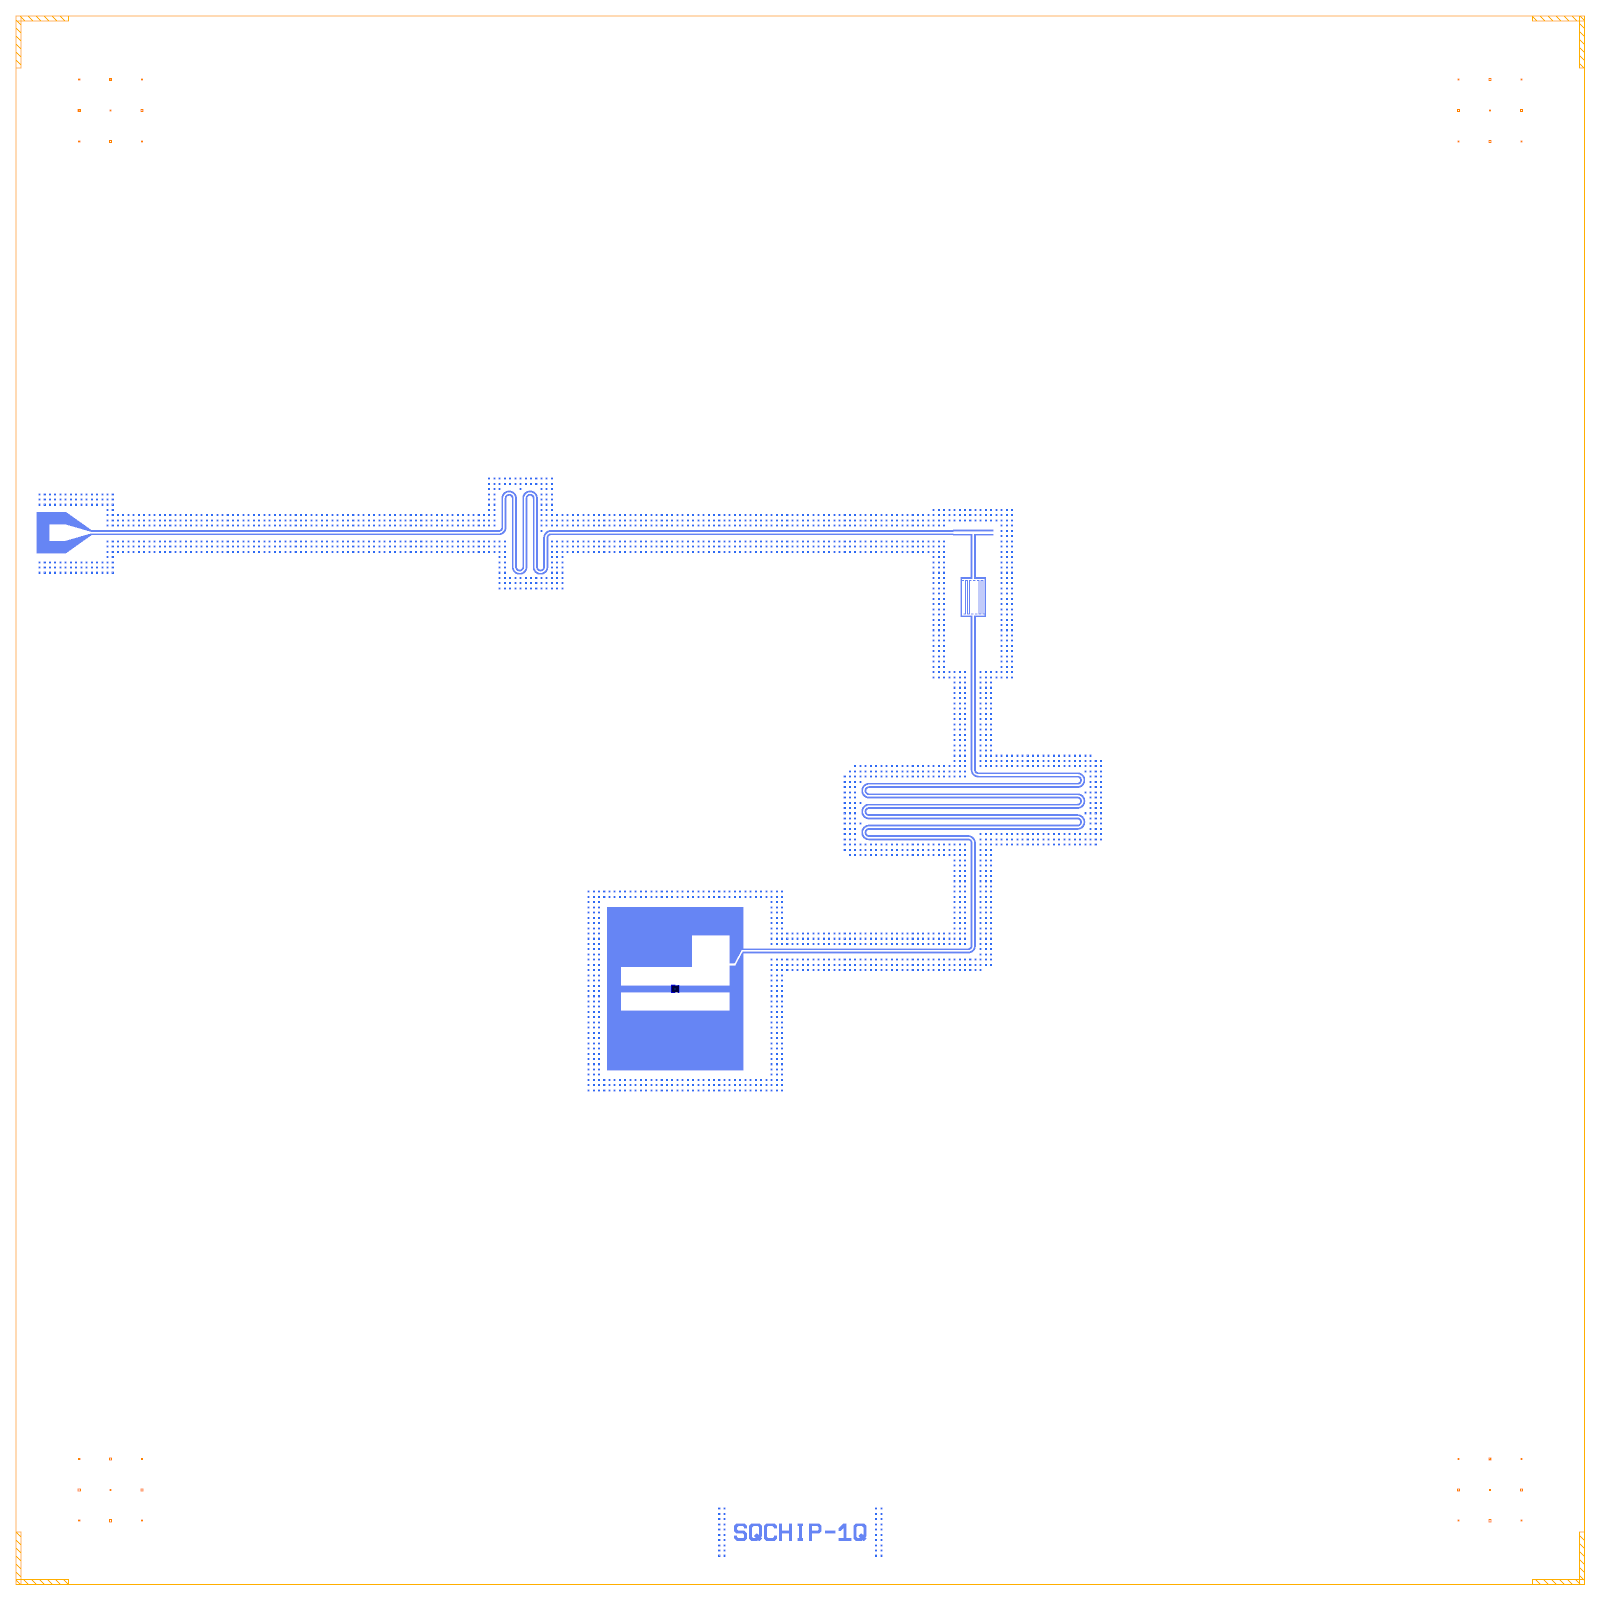

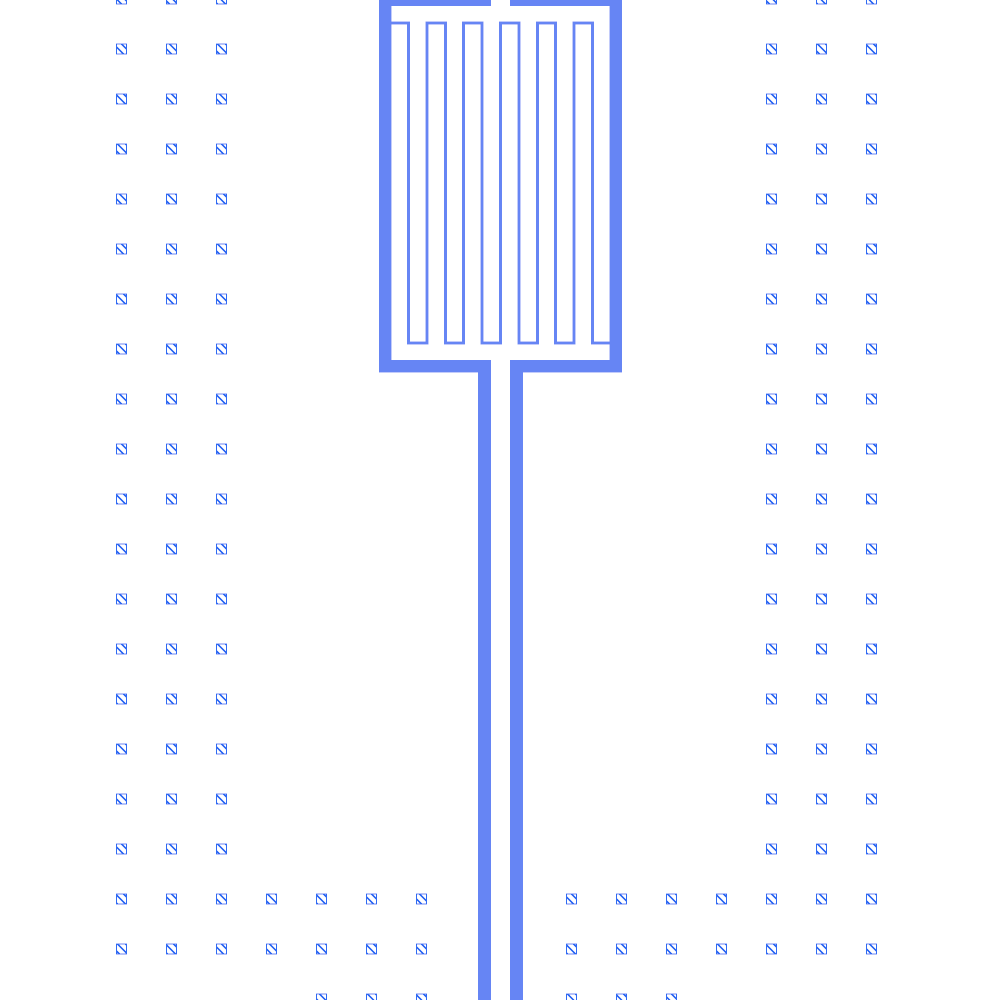

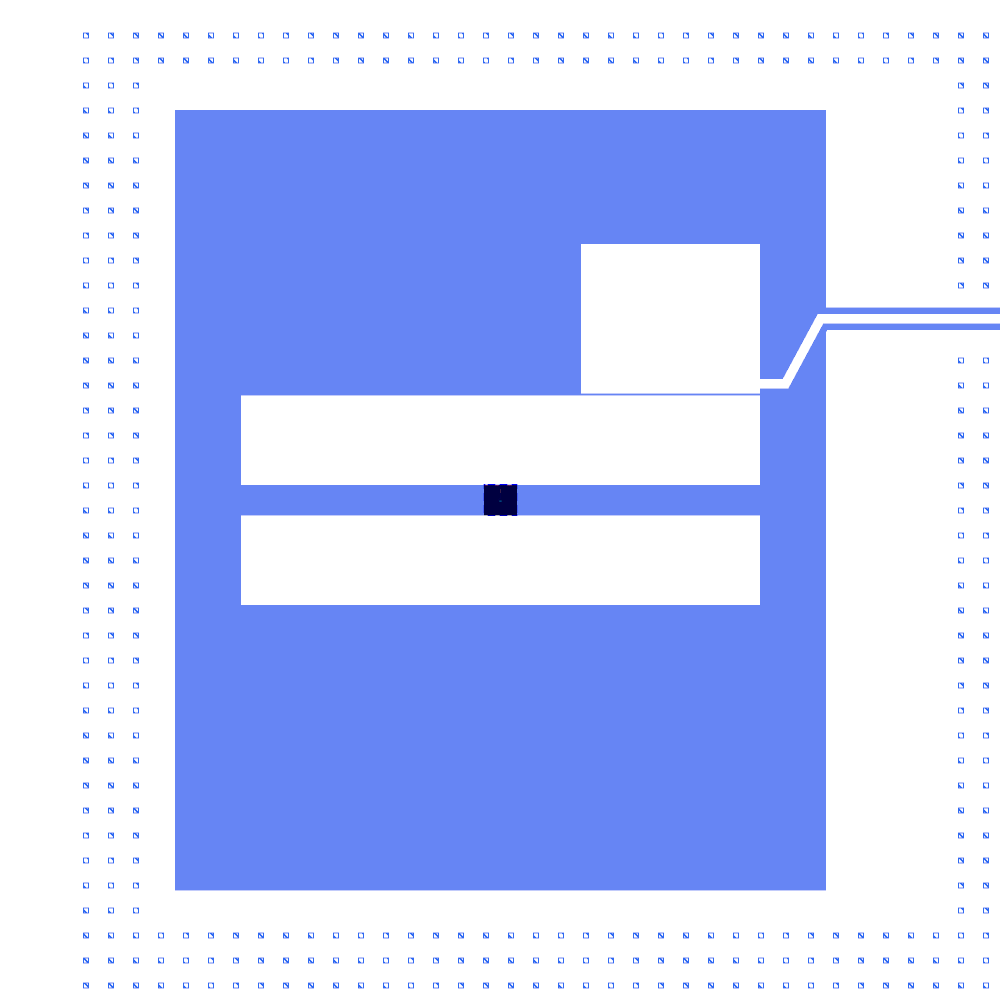

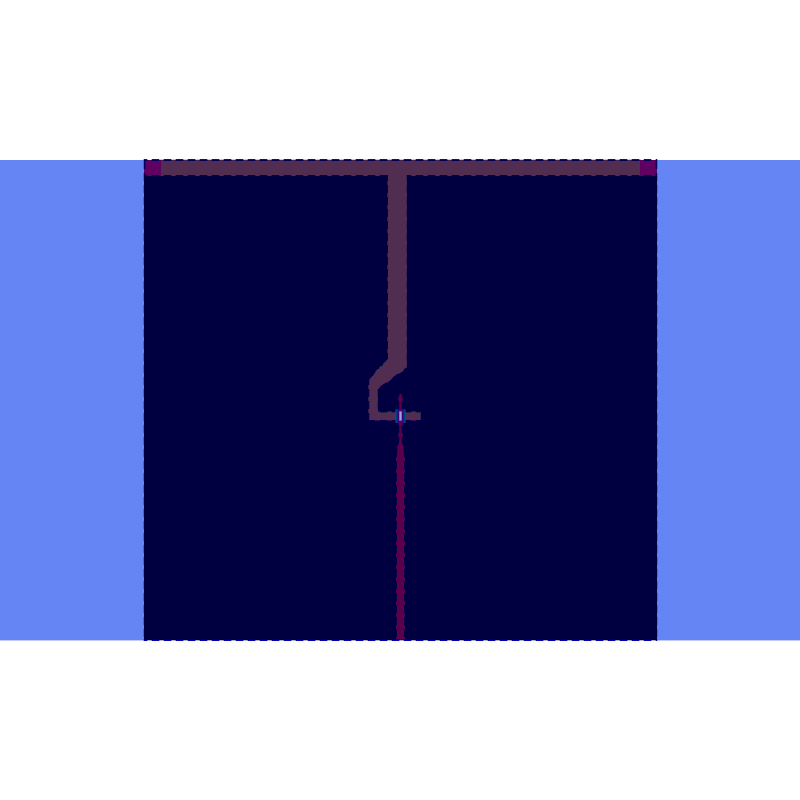

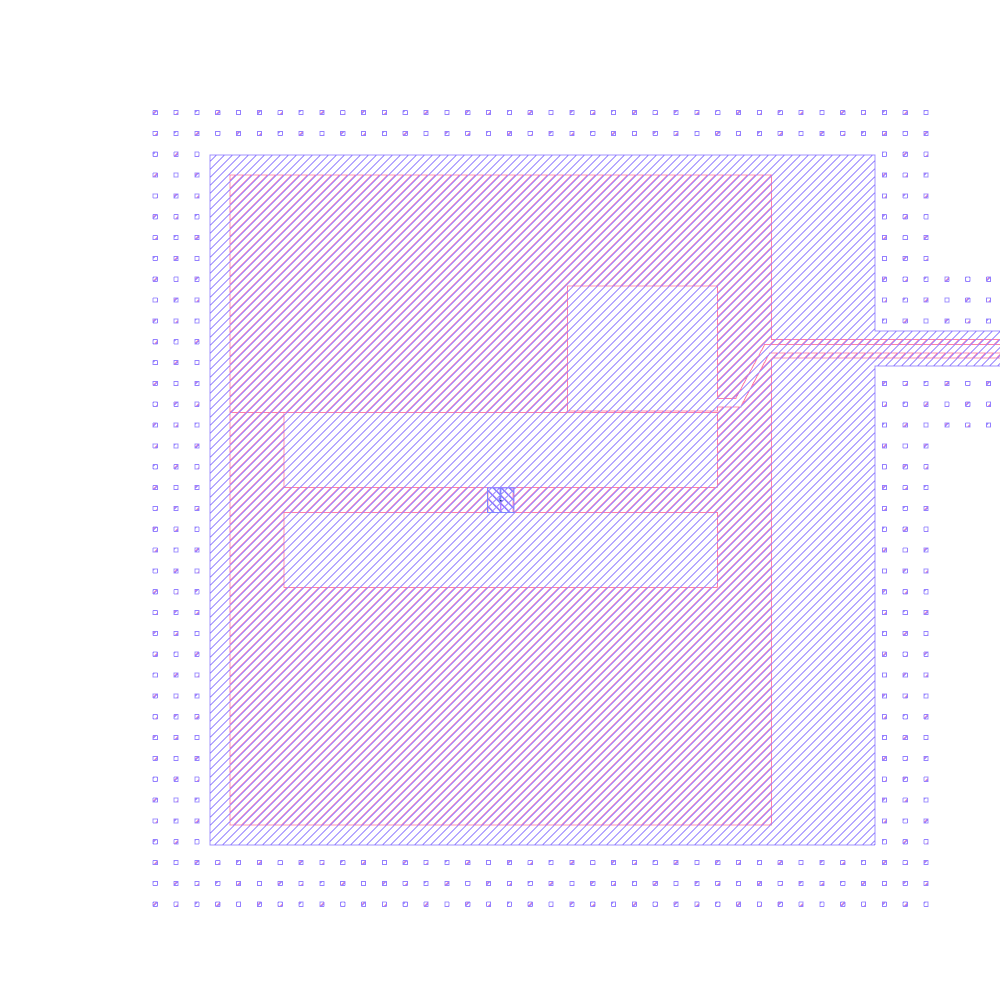

In [18]:
snap(d, OUT / "sqchip_em.png", size=(1600, 1600))
tx, ty = port_xy(d, "RO_TEE.second_end")
snap(d, OUT / "sqchip_em_tee.png", box=(tx - 250, ty - 100, tx + 250, ty + 400), size=(1000, 1000), width=400)
snap(d, OUT / "sqchip_em_q1.png", box=(qx - 500, qy - 500, qx + 500, qy + 500), size=(1000, 1000), width=400)
snap(d, OUT / "sqchip_em_jj.png", box=(qx - 25, qy - 25, qx + 25, qy + 25), size=(800, 800), width=300)   # pocket centre
snap_file(Path("build") / "sqchip_em_fab.oas", OUT / "sqchip_em_cheese.png",
          box=(qx - 600, qy - 600, qx + 600, qy + 600), size=(1000, 1000), width=400);

## 14 · Summary

- **Matches the source:** the cells and their options, the readout and feed lengths, the tee, the dataset's L_J and
  targets; f_r lands 0.4 % above the dataset's 6.099 GHz.
- **Changed by the PDK:** the 7.5 mm die and frame, sapphire, a drawn trilayer junction, the launchpad 100 µm from the
  west edge (a shorter straight before the feed meander), the core centred in the die, the PDK band cheese (the source sets
  `GDS_DISABLE_CHEESE = True`: 2550 holes in the mask).
- **Open PDK design warnings:** `pdk_rn` on Q1 (R_n 80.4 kΩ at the dataset's 12 nH; flagged, not retuned). f_q
  is 8 % above the dataset's (LOM vs HFSS).
- **Known LOM limit:** κ through the 1.2 µm-gap IDC is over-estimated (93 MHz vs 5.7 MHz); the Q3D job of `Q1R`
  replaces the estimate when it has run.